# Track B: reinforcement learning

Train a policy on the model you identified in steps 1 to 3, then fly it on the drone in MATLAB.

1. Write a Gymnasium environment around your model (like `RocketLanderEnv` in TD 4). On the drone, the
   controller measures at each step ($T_s = 0.05$ s): `t`, `z`, `vz`, `az_prev`, `z_ref`, `u_prev`
   (`az_prev`, `u_prev`: acceleration and command of the previous step), and sends $u \in [-1, 1]$.
   `reset()` and `step()` return them in `info["m"]`.
2. Train a Stable-Baselines3 agent with an `MlpPolicy` on it, then export it with
   `export_for_matlab(agent, env)` (`export_policy.py`, do not edit): it writes `policy.mat` and `traj_model.mat`.
   Docs: [Stable-Baselines3](https://stable-baselines3.readthedocs.io/), and to follow the training,
   [TensorBoard with SB3](https://stable-baselines3.readthedocs.io/en/master/guide/tensorboard.html).
3. Write the same mission and observation in `mission()` and `observation()` of `rl_controller.m`, then run
   `EINT_RL_eval` in MATLAB. Complete the TODO in the matlab files to run the mission.

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tb\SAC_30
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 54       |
|    ep_rew_mean     | -2.05    |
| time/              |          |
|    episodes        | 4        |
|    fps             | 3369     |
|    time_elapsed    | 0        |
|    total_timesteps | 216      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 46.9     |
|    ep_rew_mean     | -1.55    |
| time/              |          |
|    episodes        | 8        |
|    fps             | 3801     |
|    time_elapsed    | 0        |
|    total_timesteps | 375      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 42.7     |
|    ep_rew_mean     | -0.449   |
| time/              |          |
|    episodes        | 12       |

C:\Users\johar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


New best mean reward!
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 45.2     |
|    ep_rew_mean     | 0.102    |
| time/              |          |
|    episodes        | 128      |
|    fps             | 165      |
|    time_elapsed    | 34       |
|    total_timesteps | 5735     |
| train/             |          |
|    actor_loss      | -4.19    |
|    critic_loss     | 0.0849   |
|    ent_coef        | 0.333    |
|    ent_coef_loss   | -1.59    |
|    learning_rate   | 0.0003   |
|    n_updates       | 3734     |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 52.1     |
|    ep_rew_mean     | 2.02     |
| time/              |          |
|    episodes        | 132      |
|    fps             | 152      |
|    time_elapsed    | 42       |
|    total_timesteps | 6535     |
| train/             |          |
|    actor_loss      | -4.9     |
|    critic_loss     | 0.0

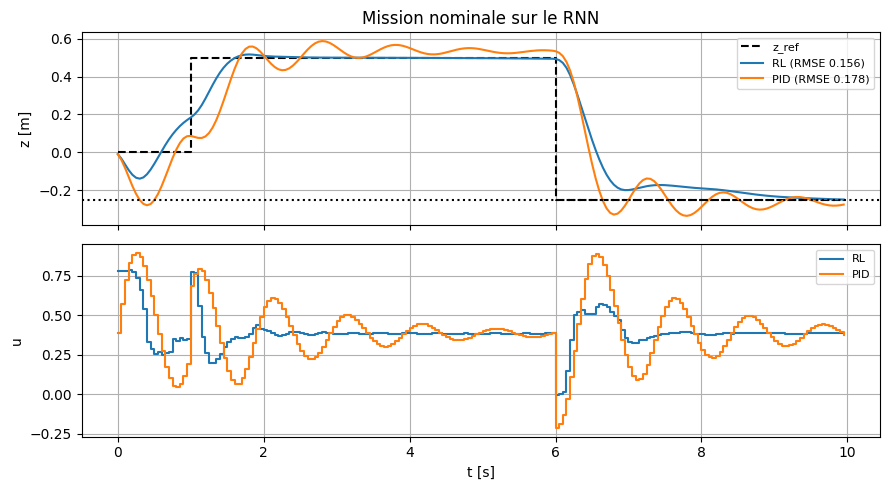

policy.mat and traj_model.mat written (200 steps): now run EINT_RL_eval in MATLAB.
Check (Python) OK : 200 pas. Lance maintenant EINT_RL_eval dans MATLAB.


In [5]:
# ====================== Track B : entraînement, export, check ======================
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import EvalCallback
import sys; sys.path.append('../../src')
from export_policy import export_for_matlab

RUN_ENV_TESTS = False
%run -i drone_env.ipynb            # DroneEnv, RNNPlant, mission, ObservationBuilder, check_like_matlab...

env_train = DroneEnv(noise=1.0, randomize=True)   # bruit + randomisation : robustesse au simulateur
env_cb    = DroneEnv()                            # suivi pendant l'entraînement (meilleur modèle)
env_eval  = DroneEnv()                            # sans bruit : pour l'export (reset(seed=0) = Fig. 1)

agent = SAC("MlpPolicy", env_train, policy_kwargs=dict(net_arch=[64, 64]), learning_starts=2000,
            ent_coef="auto",                                    # fixe : en "auto" il montait à ~6 et noyait la récompense
            verbose=1, tensorboard_log="./tb", seed=0)      # tensorboard : pip install tensorboard
eval_cb = EvalCallback(env_cb, eval_freq=5_000, n_eval_episodes=1, deterministic=True,
                       best_model_save_path="./best")
agent.learn(total_timesteps=100_000, callback=eval_cb)
import os
if os.path.exists("./best/best_model.zip"):
    agent = SAC.load("./best/best_model")     # meilleur modèle vu sur la mission nominale

# Contrôle avant export : RL contre PID, nominal puis randomisé
U_HOVER = RNNPlant().hover_command()
rl  = lambda obs, m: agent.predict(obs, deterministic=True)[0][0]
pid = lambda: make_pid(U_HOVER)
L_rl, L_pid = rollout(DroneEnv(), rl), rollout(DroneEnv(), pid())
print(summary("RL", L_rl)); print(summary("PID", L_pid))
for name, p in [("RL", lambda: rl), ("PID", pid)]:
    r = [rmse(rollout(DroneEnv(noise=1.0, randomize=True), p(), seed=s)) for s in range(20)]
    print(f"{name:3s} randomisé : RMSE moyen {np.mean(r):.3f} m, pire {np.max(r):.3f} m")
plot_logs([("RL", L_rl), ("PID", L_pid)], "Mission nominale sur le RNN")

export_for_matlab(agent, env_eval)   # env sans bruit : écrit policy.mat et traj_model.mat
check_like_matlab()                  # même check que EINT_RL_eval.m, en Python

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tb\SAC_1
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 35.8     |
|    ep_rew_mean     | 4.6      |
| time/              |          |
|    episodes        | 4        |
|    fps             | 1367     |
|    time_elapsed    | 0        |
|    total_timesteps | 143      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 29.8     |
|    ep_rew_mean     | 4.01     |
| time/              |          |
|    episodes        | 8        |
|    fps             | 1719     |
|    time_elapsed    | 0        |
|    total_timesteps | 238      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 53.7     |
|    ep_rew_mean     | 6.4      |
| time/              |          |
|    episodes        | 12       |


C:\Users\johar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


New best mean reward!
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 38.6     |
|    ep_rew_mean     | 5.28     |
| time/              |          |
|    episodes        | 124      |
|    fps             | 139      |
|    time_elapsed    | 36       |
|    total_timesteps | 5033     |
| train/             |          |
|    actor_loss      | -4.62    |
|    critic_loss     | 0.208    |
|    ent_coef        | 0.403    |
|    ent_coef_loss   | -1.49    |
|    learning_rate   | 0.0003   |
|    n_updates       | 3032     |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 37.8     |
|    ep_rew_mean     | 5.32     |
| time/              |          |
|    episodes        | 128      |
|    fps             | 137      |
|    time_elapsed    | 37       |
|    total_timesteps | 5183     |
| train/             |          |
|    actor_loss      | -4.72    |
|    critic_loss     | 0.2

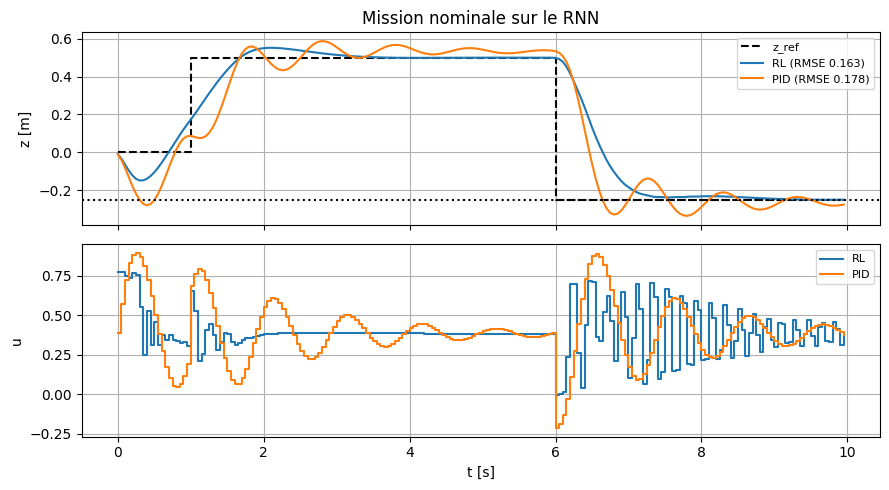


Robustesse (10 vols par scénario) :
aucun              RL  RMSE 0.162 | pire min z -0.268
aucun              PID RMSE 0.177 | pire min z -0.355
retard 50 ms       RL  RMSE 0.179 | pire min z -0.348
retard 50 ms       PID RMSE 0.204 | pire min z -0.575
retard 100 ms      RL  RMSE 0.232 | pire min z -0.615
retard 100 ms      PID RMSE 0.467 | pire min z -1.292
perte cmd 30 %     RL  RMSE 0.186 | pire min z -0.763
perte cmd 30 %     PID RMSE 0.228 | pire min z -1.767
perte mesure 30 %  RL  RMSE 0.169 | pire min z -0.582
perte mesure 30 %  PID RMSE 0.188 | pire min z -0.679
rafales 2 m/s²     RL  RMSE 0.171 | pire min z -0.348
rafales 2 m/s²     PID RMSE 0.206 | pire min z -0.654
effet de sol       RL  RMSE 0.162 | pire min z -0.264
effet de sol       PID RMSE 0.189 | pire min z -0.332
batterie -10 %     RL  RMSE 0.161 | pire min z -0.270
batterie -10 %     PID RMSE 0.176 | pire min z -0.426
vz par dz/Ts       RL  RMSE 0.162 | pire min z -0.296
vz par dz/Ts       PID RMSE 0.189 | pire min 

In [2]:
# ====================== Track B : entraînement, export, check ======================
import os
import numpy as np
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import EvalCallback
import sys; sys.path.append('../../src')
from export_policy import export_for_matlab

RUN_ENV_TESTS = False
%run -i drone_env.ipynb            # DroneEnv (avec les défauts réels), RNNPlant, mission, ...

# Défauts réels pendant l'entraînement (env_eval reste SANS défaut : export et check inchangés)
TRAIN_DEFECTS = dict(delay_max=2, p_loss_cmd=0.1, p_loss_meas=0.1, gust_std=1.0,
                     ground_k=0.1, gain_drift=0.05, quant_bits=8)

env_train = DroneEnv(noise=1.0, randomize=True, defects=TRAIN_DEFECTS)
env_cb    = DroneEnv()                            # suivi pendant l'entraînement (meilleur modèle)
env_eval  = DroneEnv()                            # sans bruit ni défaut : pour l'export

agent = SAC("MlpPolicy", env_train, policy_kwargs=dict(net_arch=[64, 64]), learning_starts=2000,
            verbose=1, tensorboard_log="./tb", seed=0)
eval_cb = EvalCallback(env_cb, eval_freq=5_000, n_eval_episodes=1, deterministic=True,
                       best_model_save_path="./best")
agent.learn(total_timesteps=30_000, callback=eval_cb)
if os.path.exists("./best/best_model.zip"):
    agent = SAC.load("./best/best_model")

# Contrôle : RL contre PID sur la mission nominale
U_HOVER = RNNPlant().hover_command()
rl  = lambda obs, m: agent.predict(obs, deterministic=True)[0][0]
pid = lambda: make_pid(U_HOVER)
L_rl, L_pid = rollout(DroneEnv(), rl), rollout(DroneEnv(), pid())
print(summary("RL", L_rl)); print(summary("PID", L_pid))
plot_logs([("RL", L_rl), ("PID", L_pid)], "Mission nominale sur le RNN")

# Robustesse : un défaut à la fois, 10 vols chacun
print("\nRobustesse (10 vols par scénario) :")
for name, d in [("aucun", {}), ("retard 50 ms", dict(delay_max=1)), ("retard 100 ms", dict(delay_max=2)),
                ("perte cmd 30 %", dict(p_loss_cmd=0.3)), ("perte mesure 30 %", dict(p_loss_meas=0.3)),
                ("rafales 2 m/s²", dict(gust_std=2.0)), ("effet de sol", dict(ground_k=0.15)),
                ("batterie -10 %", dict(gain_drift=0.1)), ("vz par dz/Ts", dict(vz_from_z=True))]:
    for p_name, p in [("RL", lambda: rl), ("PID", pid)]:
        Ls = [rollout(DroneEnv(noise=1.0, defects=d), p(), seed=s) for s in range(10)]
        print(f"{name:18s} {p_name:3s} RMSE {np.mean([rmse(L) for L in Ls]):.3f} | "
              f"pire min z {min(L['z'].min() for L in Ls):+.3f}")

export_for_matlab(agent, env_eval)   # écrit policy.mat et traj_model.mat
check_like_matlab()                  # même check que EINT_RL_eval.m, en Python

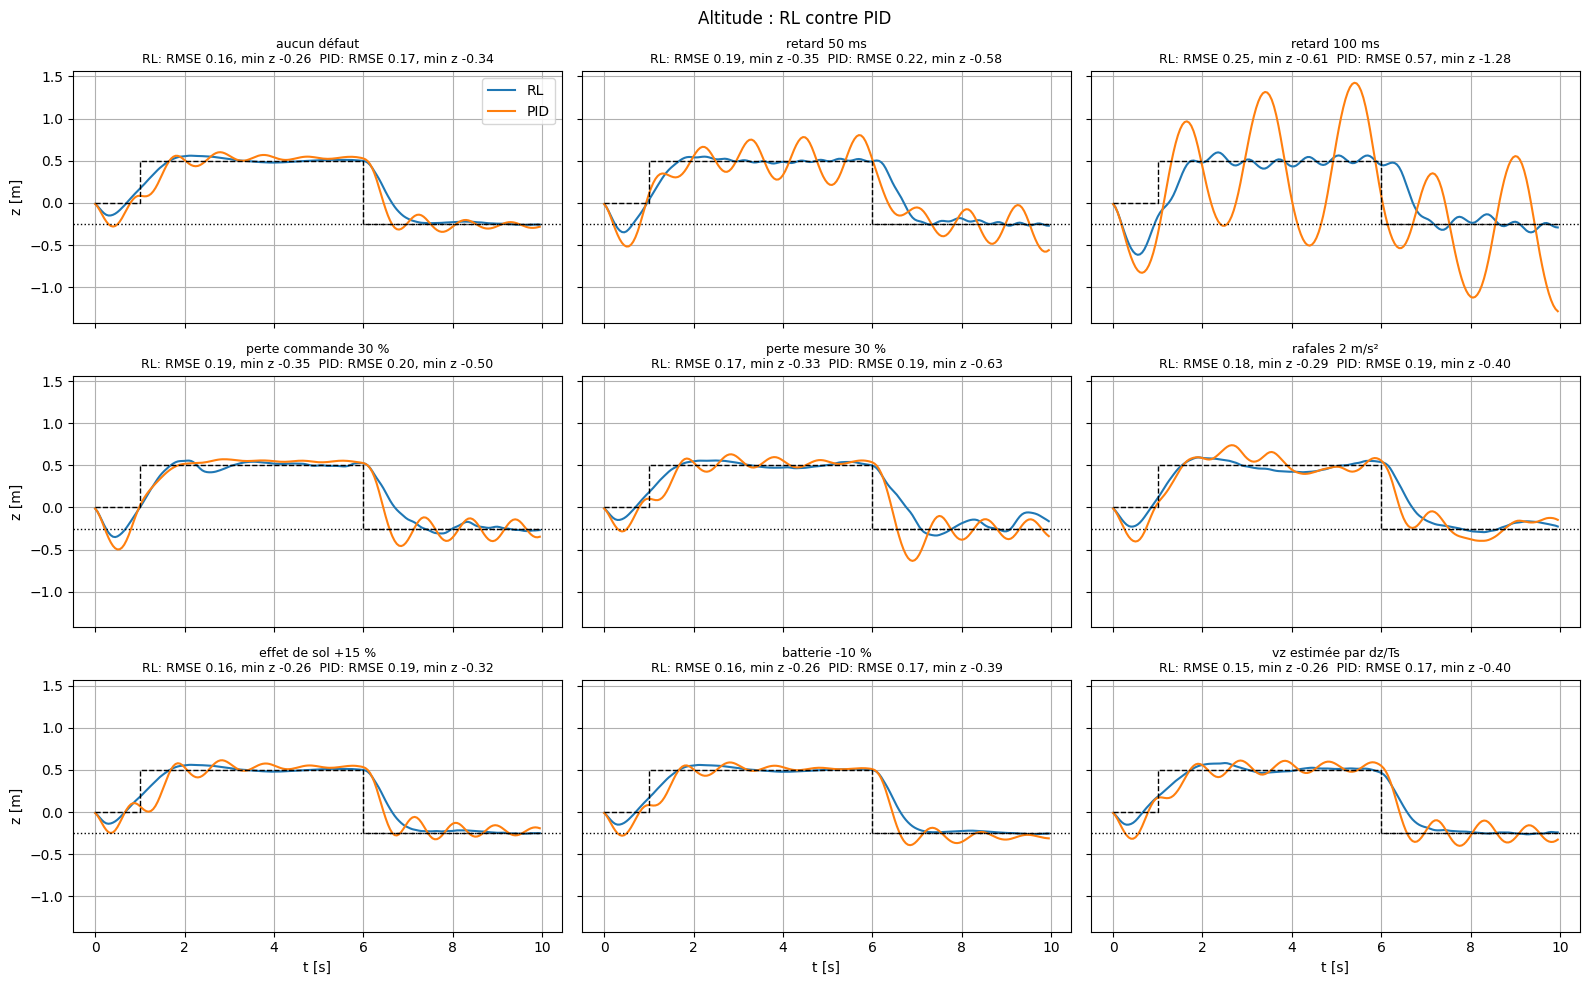

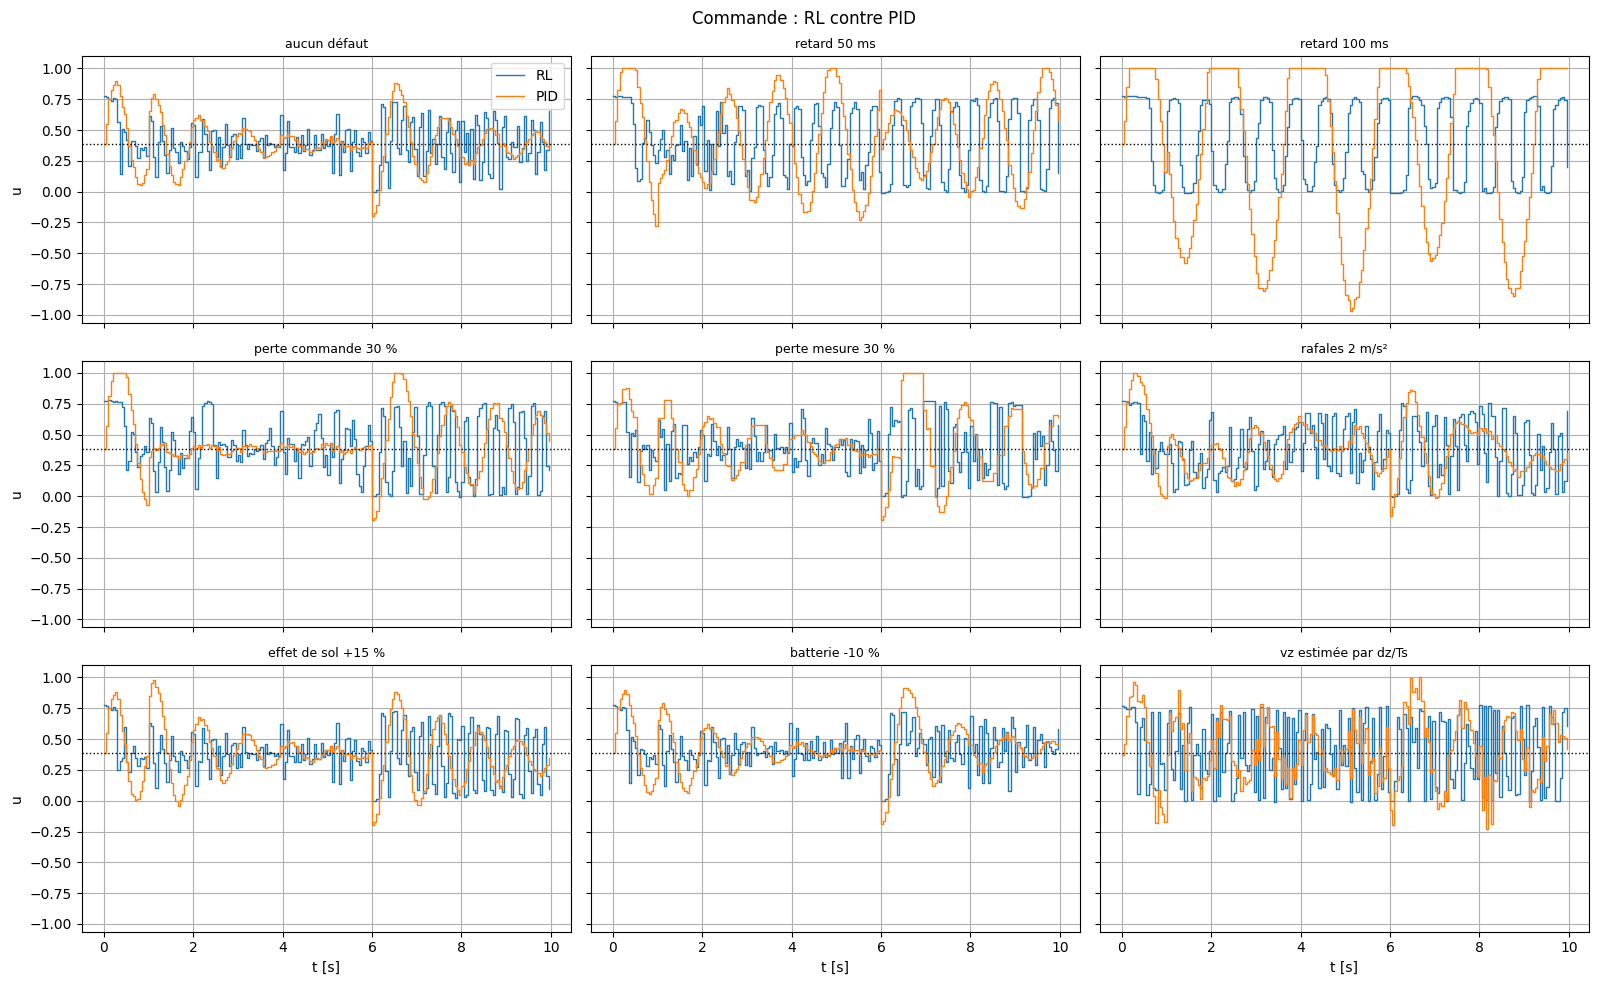

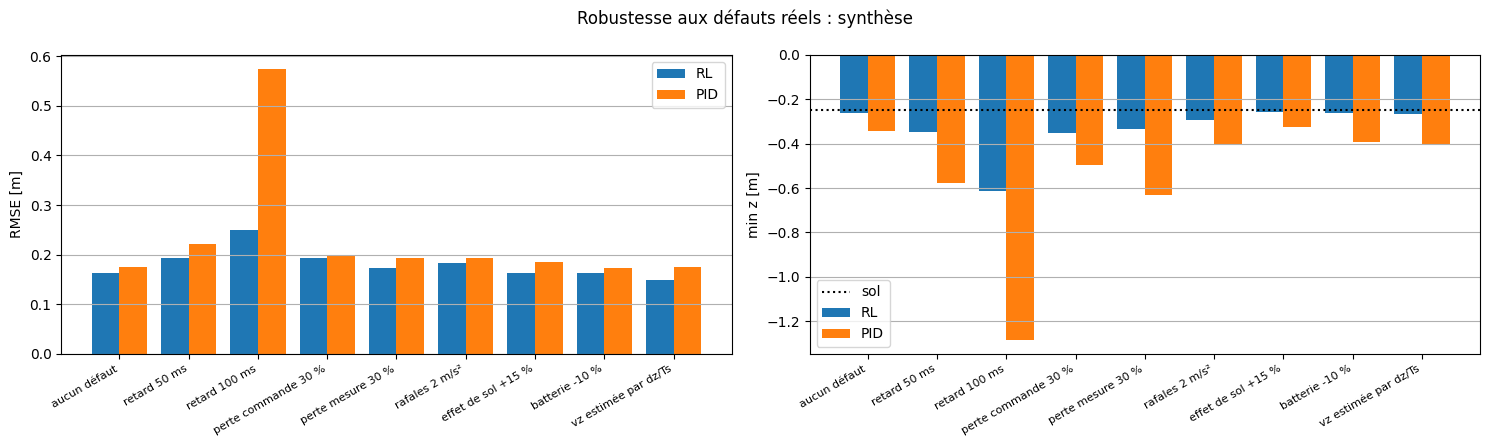

In [3]:
# ===== Courbes de robustesse : 1 vol RL + 1 vol PID par scénario (pas besoin de réentraîner) =====
if "agent" not in globals():                      # noyau redémarré : on recharge la politique entraînée
    RUN_ENV_TESTS = False
    %run -i drone_env.ipynb
    from stable_baselines3 import SAC
    agent = SAC.load("./best/best_model")
U_HOVER = RNNPlant().hover_command()
rl  = lambda obs, m: agent.predict(obs, deterministic=True)[0][0]
pid = lambda: make_pid(U_HOVER)

class FixedDelayEnv(DroneEnv):
    # Même env, mais avec un retard FIXE (au lieu d'un tirage aléatoire 0..delay_max)
    def __init__(self, delay=0, **kw):
        super().__init__(**kw); self.fixed_delay = delay
    def reset(self, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        self.delay = self.fixed_delay; self.u_queue = [0.0] * self.delay
        return obs, info

# (nom, défauts, retard fixe en pas)
scenarios = [("aucun défaut", {}, 0), ("retard 50 ms", {}, 1), ("retard 100 ms", {}, 2),
             ("perte commande 30 %", dict(p_loss_cmd=0.3), 0), ("perte mesure 30 %", dict(p_loss_meas=0.3), 0),
             ("rafales 2 m/s²", dict(gust_std=2.0), 0), ("effet de sol +15 %", dict(ground_k=0.15), 0),
             ("batterie -10 %", dict(gain_drift=0.1), 0), ("vz estimée par dz/Ts", dict(vz_from_z=True), 0)]
SEED = 0                                          # même graine pour RL et PID : mêmes perturbations

res = {}
figz, axz = plt.subplots(3, 3, figsize=(16, 10), sharex=True, sharey=True)
figu, axu = plt.subplots(3, 3, figsize=(16, 10), sharex=True, sharey=True)
for i, (name, d, dly) in enumerate(scenarios):
    a_z, a_u = axz.flat[i], axu.flat[i]
    res[name] = {}
    for p_name, p, col in [("RL", lambda: rl, "C0"), ("PID", pid, "C1")]:
        L = rollout(FixedDelayEnv(delay=dly, noise=1.0, defects=d), p(), seed=SEED)
        res[name][p_name] = (rmse(L), L["z"].min())
        a_z.plot(L["t"], L["z"], col, lw=1.5, label=p_name)
        a_u.step(L["t"], L["u"], col, where="post", lw=1, label=p_name)
    a_z.step(L["t"], L["z_ref"], "k--", where="post", lw=1)
    a_z.axhline(Z_GROUND, c="k", ls=":", lw=1)
    a_u.axhline(U_HOVER, c="k", ls=":", lw=1)
    txt = "  ".join(f"{k}: RMSE {r:.2f}, min z {mz:+.2f}" for k, (r, mz) in res[name].items())
    a_z.set_title(f"{name}\n{txt}", fontsize=9); a_u.set_title(name, fontsize=9)
    a_z.grid(); a_u.grid()
for fig, axes, ylab, title, fname in [(figz, axz, "z [m]", "Altitude : RL contre PID", "robustesse_z.png"),
                                      (figu, axu, "u", "Commande : RL contre PID", "robustesse_u.png")]:
    axes[0, 0].legend()
    for a in axes[-1]: a.set_xlabel("t [s]")
    for a in axes[:, 0]: a.set_ylabel(ylab)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(fname, dpi=150)

# ----- Synthèse : RMSE et min z par scénario -----
names = [n for n, _, _ in scenarios]; x = np.arange(len(names))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for p_name, off, col in [("RL", -0.2, "C0"), ("PID", 0.2, "C1")]:
    ax[0].bar(x + off, [res[n][p_name][0] for n in names], 0.4, color=col, label=p_name)
    ax[1].bar(x + off, [res[n][p_name][1] for n in names], 0.4, color=col, label=p_name)
ax[0].set_ylabel("RMSE [m]"); ax[1].set_ylabel("min z [m]")
ax[1].axhline(Z_GROUND, c="k", ls=":", label="sol")
for a in ax:
    a.set_xticks(x); a.set_xticklabels(names, rotation=30, ha="right", fontsize=8); a.grid(axis="y"); a.legend()
fig.suptitle("Robustesse aux défauts réels : synthèse"); fig.tight_layout(); fig.savefig("robustesse_synthese.png", dpi=150)
plt.show()